# 26 Einstufung mit K-Means: Läuft eine Station im Optimum oder schlechter?

Teil 6: Lernende Modelle

**Worum es geht**

Der Projektpartner hat drei Klassen mit je einer Empfehlung vorgegeben. Läuft eine Station gut, besteht kein Handlungsbedarf. Läuft sie schlechter als möglich, obwohl die Technik in Ordnung ist, sollen die Regelparameter optimiert werden. Schließt das Regelventil nicht, muss es getauscht werden. Das Ventil erkennen die Modelle in Notebook 27 und 29. Für die übrigen Stationen bleibt die Frage, ob sie im Optimum laufen oder schlechter.

Dafür braucht es kein Label. K-Means gruppiert die Stationen nach ihrem Regelverhalten, und die Gruppe mit dem kältesten Rücklauf gilt als Optimum, an dem sich die anderen messen. Allgemeines Clustering hat im Projekt keine brauchbaren Gruppen gefunden, [Notebook 07](../3_clustering/07_stationscluster.ipynb) kam mit allen Kennzahlen auf eine Silhouette unter 0,25. Hier bekommt K-Means deshalb nur die drei Größen, die beschreiben, wie eine Station regelt, und wird danach an den Begehungen geprüft.

**Daten**
- liest: `modell_kennzahlen.csv`, `modell_labels.csv` und `modell_stunden.parquet` aus Notebook 25
- schreibt: `data/processed/kmeans_einstufung.csv` mit Gruppe und Einstufung je Zähler, gebraucht in Notebook 29
- vorher ausführen: Notebook 25

## 1 Daten laden

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

kz = pd.read_csv(PROCESSED / "modell_kennzahlen.csv", index_col="zaehler")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
print(f"Kennzahlen: {kz.shape[0]} Zähler × {kz.shape[1]} Spalten")
print(f"Labels:     {labels.shape[0]} begangene Zähler × {labels.shape[1]} Spalten")
kz.head()

Kennzahlen: 91 Zähler × 16 Spalten
Labels:     56 begangene Zähler × 11 Spalten


,stunden_winter,stunden_sommer,sommer_nachtfluss_lph,sommer_durchlauf_anteil,sommer_nacht_spreizung_k,winter_ruecklauf_bei_0c,winter_spreizung_last_k,winter_ruecklauf_p90,winter_fluss_cv,winter_nacht_tag_fluss,sommerlast_anteil,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet,auslastung,auslastung_vertrag
zaehler,,,,,,,,,,,,,,,,
53198226,3467.0,2206.0,10.0,0.657609,14.2,44.779441,32.069805,54.5,0.647601,0.339623,0.102304,0.962280,0.830796,42.945283,1.31201,NaN
58177363,4389.0,0.0,NaN,NaN,NaN,42.136805,32.330807,47.6,0.622559,0.622807,NaN,0.844506,0.596419,39.223518,NaN,NaN
58177384,923.0,0.0,NaN,NaN,NaN,57.144011,25.307972,57.5,0.467353,0.580292,NaN,1.167188,0.588327,51.064065,NaN,NaN
58202380,4386.0,0.0,NaN,NaN,NaN,56.753281,NaN,68.2,NaN,1.080556,NaN,NaN,NaN,NaN,NaN,NaN
61620222,4391.0,0.0,NaN,NaN,NaN,46.590106,24.538290,58.5,0.713799,0.000000,NaN,0.973293,0.908761,44.579588,NaN,NaN


In [2]:
labels.head()

,begehungen,erste_begehung,strasse_gruppe,vertrag_alt_kw,vertrag_neu_kw,ventil,daemmung,filter,durchfluss,temperatur,ueberdimensioniert
zaehler,,,,,,,,,,,
65273846,1,NaT,8,8.0,8.0,False,True,False,False,False,0.0
68956339,1,2024-11-25,3,NaN,NaN,False,False,True,True,True,NaN
68956342,2,2024-09-18,7,NaN,NaN,False,True,True,False,True,NaN
68956344,1,2024-09-20,7,8.0,8.0,False,False,False,False,True,0.0
68956345,1,2024-09-18,13,14.0,14.0,False,False,True,False,True,0.0


`kz` hat eine Zeile je Zähler (91) mit den Kennzahlen aus Notebook 25. Einige Felder sind leer, wo im Winter oder Sommer zu wenig gemessen wurde. `labels` hat eine Zeile je begangenem Zähler (56) mit Datum, Straßennummer, Vertragswerten und sechs Labels, nicht begangene Zähler fehlen dort.

In [3]:
MERKMALE = ["anteil_volumenstrom", "streubreite_betriebspunkte", "ruecklauf_lastgewichtet"]
daten = kz[MERKMALE].dropna()
print(f"{len(daten)} von {len(kz)} Zählern haben alle drei Kennzahlen")
daten.describe().round(2)

88 von 91 Zählern haben alle drei Kennzahlen


,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet
count,88.00,88.00,88.00
mean,0.82,0.72,46.31
std,0.36,0.17,8.61
min,-0.09,0.19,30.72
25%,0.74,0.62,41.23
50%,0.91,0.72,45.33
75%,1.04,0.83,51.09
max,1.44,1.16,69.18


Für die Einstufung zählen nur die drei Größen, die beschreiben, wie eine Station regelt. Alle drei stammen aus dem Winter 23/24, also aus der Zeit vor den Begehungen:

| Kennzahl | hoch heißt | niedrig heißt |
|---|---|---|
| `anteil_volumenstrom` | Durchfluss folgt der Last (gut) | Durchfluss läuft konstant, das Ventil drosselt nicht |
| `streubreite_betriebspunkte` | Betriebspunkte springen | gleichbleibender Betrieb |
| `ruecklauf_lastgewichtet` | Wasser kommt heiß zurück (schlecht) | gute Auskühlung |

Zähler mit weniger als 200 Laststunden im Winter haben keine Werte und werden nicht eingestuft.

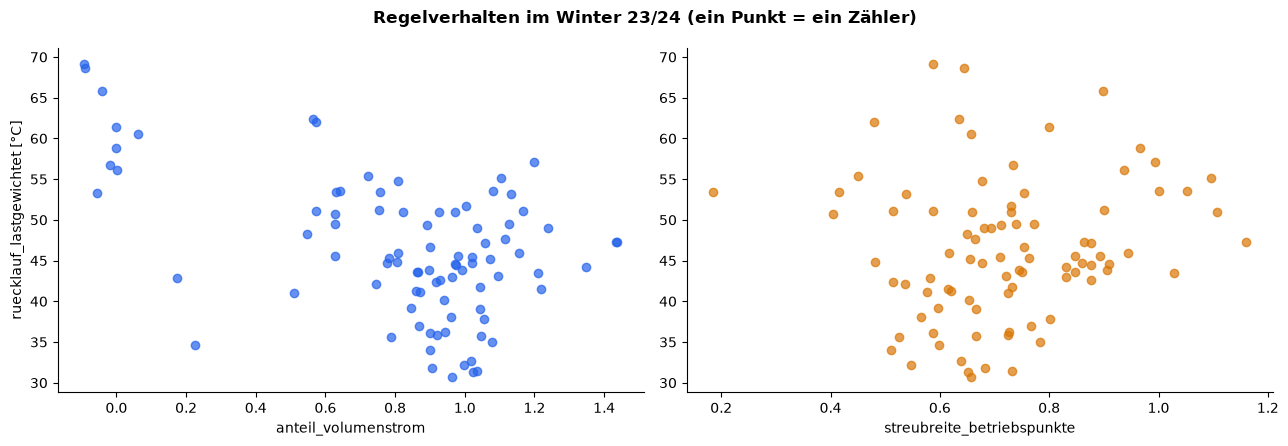

Korrelationen:


,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet
anteil_volumenstrom,1.00,0.16,-0.52
streubreite_betriebspunkte,0.16,1.00,0.12
ruecklauf_lastgewichtet,-0.52,0.12,1.00


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(daten["anteil_volumenstrom"], daten["ruecklauf_lastgewichtet"], color="#2563EB", alpha=0.7)
axes[0].set_xlabel("anteil_volumenstrom")
axes[0].set_ylabel("ruecklauf_lastgewichtet [°C]")
axes[1].scatter(daten["streubreite_betriebspunkte"], daten["ruecklauf_lastgewichtet"], color="#D97706", alpha=0.7)
axes[1].set_xlabel("streubreite_betriebspunkte")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Regelverhalten im Winter 23/24 (ein Punkt = ein Zähler)", fontweight="bold")
fig.tight_layout()
plt.show()
print("Korrelationen:")
daten.corr().round(2)

Die Grafik zeigt die Rohdaten, bevor K-Means sie sieht: links den Durchflussanteil gegen den Rücklauf, rechts die Streubreite gegen den Rücklauf.

Links oben sitzt eine eigene Wolke mit `anteil_volumenstrom` um 0 und einem Rücklauf zwischen 55 und 70 °C. Dort läuft der Durchfluss konstant, egal wie viel Wärme gebraucht wird, und das Wasser kommt heiß zurück. Die Korrelation bestätigt das, Durchflussanteil und Rücklauf hängen mit −0,52 zusammen. Die Streubreite hängt mit keiner der beiden Größen stark zusammen (0,16 und 0,12).

## 2 Vorverarbeitung

K-Means misst euklidische Abstände. Ohne Skalierung würde der Rücklauf mit einer Spanne von rund 30 K die beiden anderen Größen mit einer Spanne von rund 1 überdecken. Deshalb bekommt jede Kennzahl den Mittelwert 0 und die Standardabweichung 1.

In [5]:
skalierer = StandardScaler()
X = skalierer.fit_transform(daten)
pd.DataFrame(X, columns=MERKMALE, index=daten.index).describe().round(2).loc[["mean", "std", "min", "max"]]

,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet
mean,0.00,-0.00,-0.00
std,1.01,1.01,1.01
min,-2.56,-3.15,-1.82
max,1.73,2.59,2.67


`StandardScaler` zieht je Spalte den Mittelwert ab und teilt durch die Standardabweichung. Zur Kontrolle stehen danach in allen drei Spalten Mittelwert 0 und Streuung 1.

## 3 Wie viele Gruppen? Elbow und Silhouette

K-Means wird für k = 2 bis 6 gerechnet, jeweils mit 25 Startpunkten (`n_init`), und je k zählt die beste Lösung. Die Elbow-Kurve zeigt, wo die Summe der Abstände abknickt, ab dort bringt eine weitere Gruppe wenig. Die Silhouette misst je Station, ob sie ihrer eigenen Gruppe näher ist als der nächsten. 1 wäre perfekt, 0 heißt genau dazwischen. Gewählt wird das k mit der besten Silhouette.

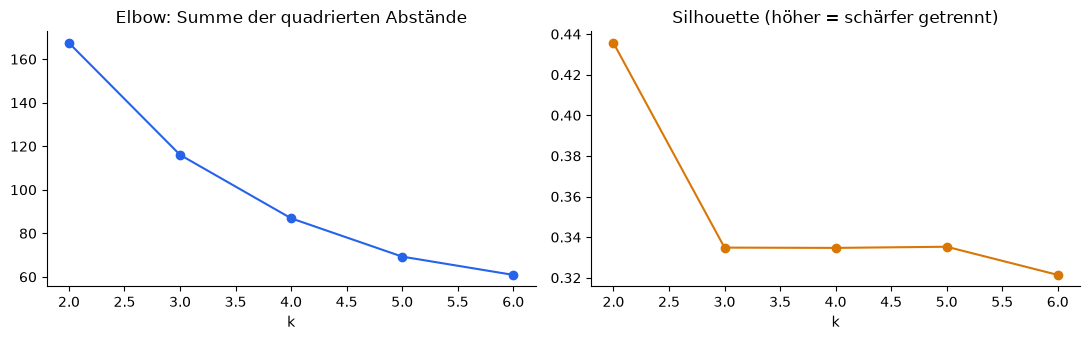

Beste Silhouette bei k = 2: 0.436


,inertia,silhouette
k,,
2,167.455,0.436
3,116.048,0.335
4,86.896,0.335
5,69.294,0.335
6,60.898,0.321


In [6]:
suche = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=25, random_state=0).fit(X)
    suche.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_)})
suche = pd.DataFrame(suche).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(suche.index, suche["inertia"], "o-", color="#2563EB")
axes[0].set_title("Elbow: Summe der quadrierten Abstände")
axes[1].plot(suche.index, suche["silhouette"], "o-", color="#D97706")
axes[1].set_title("Silhouette (höher = schärfer getrennt)")
for ax in axes:
    ax.set_xlabel("k")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

K = int(suche["silhouette"].idxmax())
print(f"Beste Silhouette bei k = {K}: {suche.loc[K, 'silhouette']:.3f}")
suche.round(3)

k = 2 ist klar am besten, mit einer Silhouette von 0,44. Ab k = 3 fällt sie auf rund 0,33 und bleibt dort. Die Elbow-Kurve hat keinen scharfen Knick, sie bestätigt also nichts, widerspricht aber auch nicht. Zwei Gruppen passen zur Frage, Optimum und schlechter. Zum Vergleich: [Notebook 07](../3_clustering/07_stationscluster.ipynb) kam mit allen Kennzahlen auf eine Silhouette unter 0,25. Mit den drei Regelungsgrößen sind die Gruppen deutlich schärfer getrennt.

## 4 K-Means rechnen und die Gruppen benennen

Die Zelle rechnet K-Means mit dem gewählten k und benennt die Gruppen nach ihrem Rücklauf. A ist die Gruppe mit dem kältesten Rücklauf, also das Optimum, alle anderen gelten als „schlechter“. Die Tabelle zeigt die Gruppenmitten in echten Einheiten.

In [7]:
km = KMeans(n_clusters=K, n_init=25, random_state=0).fit(X)
daten["cluster"] = km.labels_

reihenfolge = daten.groupby("cluster")["ruecklauf_lastgewichtet"].mean().sort_values().index
namen = {c: chr(ord("A") + i) for i, c in enumerate(reihenfolge)}
daten["gruppe"] = daten["cluster"].map(namen)
daten["einstufung"] = np.where(daten["gruppe"] == "A", "Optimum", "schlechter")

zentren = pd.DataFrame(skalierer.inverse_transform(km.cluster_centers_), columns=MERKMALE)
zentren["gruppe"] = [namen[c] for c in range(K)]
profil = zentren.set_index("gruppe").sort_index()
profil["Zähler"] = daten["gruppe"].value_counts().sort_index()
profil.round(2)

,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet,Zähler
gruppe,,,,
A,0.96,0.75,43.50,70
B,0.27,0.63,57.22,18


| Gruppe | Zähler | Durchflussanteil | Rücklauf | Bedeutung |
|---|---|---|---|---|
| A, Optimum | 70 | 0,96 | 43,5 °C | Durchfluss folgt der Last, das Wasser wird gut ausgekühlt |
| B, schlechter | 18 | 0,27 | 57,2 °C | Durchfluss läuft fast konstant, Rücklauf rund 14 K heißer |

Getrennt wird vor allem über Durchflussanteil und Rücklauf, die Streubreite unterscheidet sich kaum (0,75 gegen 0,63). Gruppe B entspricht der ineffizienten Klasse des Projektpartners: Die Station regelt nicht über den Durchfluss, weil das Regelventil nicht drosselt oder falsch eingestellt ist.

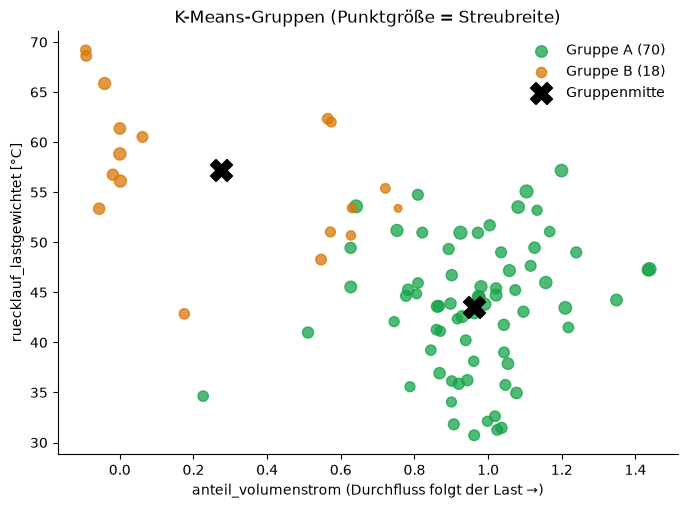

In [8]:
farben = {chr(ord("A") + i): f for i, f in enumerate(["#16A34A", "#D97706", "#DC2626", "#7C3AED", "#0891B2", "#64748B"])}
fig, ax = plt.subplots(figsize=(8, 5.5))
for name, g in daten.groupby("gruppe"):
    ax.scatter(g["anteil_volumenstrom"], g["ruecklauf_lastgewichtet"], s=20 + 60 * g["streubreite_betriebspunkte"],
               color=farben[name], alpha=0.75, label=f"Gruppe {name} ({len(g)})")
ax.scatter(profil["anteil_volumenstrom"], profil["ruecklauf_lastgewichtet"], marker="X", s=250, color="black", label="Gruppenmitte")
ax.set_xlabel("anteil_volumenstrom (Durchfluss folgt der Last →)")
ax.set_ylabel("ruecklauf_lastgewichtet [°C]")
ax.set_title("K-Means-Gruppen (Punktgröße = Streubreite)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Die Grafik zeigt die Gruppen in den zwei anschaulichsten Achsen. Die dritte Größe, die Streubreite, steckt in der Punktgröße.

## 5 Wie stabil sind die Gruppen?

Zwei Fragen sind hier wichtig. Hängt das Ergebnis am Zufallsstart? Mit 25 Starts je Lauf sollte bei jedem Seed dieselbe Einteilung herauskommen, geprüft wird das mit 20 Seeds. Und hängt es an einzelnen Stationen? Dafür zieht ein Bootstrap 200-mal Stationen mit Zurücklegen, manche doppelt und manche gar nicht, rechnet K-Means darauf neu und ordnet alle Stationen der nächsten Gruppenmitte zu. Das Optimum wird dabei jedes Mal neu über den kältesten Rücklauf bestimmt. Gemessen wird mit dem Adjusted Rand Index (ARI, 1 heißt identische Einteilung, 0 nicht besser als Zufall) und mit dem Anteil der Stationen, deren Einstufung gleich bleibt.

In [9]:
seeds = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=25, random_state=s).fit(X).labels_)
         for s in range(20)]
print(f"1) 20 Seeds: ARI Minimum {np.min(seeds):.2f} (1 = immer dieselbe Einteilung)")

rng = np.random.default_rng(0)
optimum = daten["einstufung"].eq("Optimum").to_numpy()
ari, gleich = [], []
for _ in range(200):
    stichprobe = rng.integers(0, len(X), len(X))
    km_b = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X[stichprobe])
    neu = km_b.predict(X)
    ari.append(adjusted_rand_score(km.labels_, neu))
    opt_b = np.argmin(skalierer.inverse_transform(km_b.cluster_centers_)[:, MERKMALE.index("ruecklauf_lastgewichtet")])
    gleich.append(np.mean((neu == opt_b) == optimum))
print(f"2) 200 Bootstrap-Stichproben: ARI Median {np.median(ari):.2f}, 5-%-Quantil {np.quantile(ari, 0.05):.2f}")
print(f"   gleiche Einstufung Optimum/schlechter: im Median {np.median(gleich):.0%} der Stationen, "
      f"im schlechtesten Zwanzigstel {np.quantile(gleich, 0.05):.0%}")

1) 20 Seeds: ARI Minimum 1.00 (1 = immer dieselbe Einteilung)


2) 200 Bootstrap-Stichproben: ARI Median 0.90, 5-%-Quantil 0.12
   gleiche Einstufung Optimum/schlechter: im Median 98% der Stationen, im schlechtesten Zwanzigstel 70%


Der Zufallsstart spielt keine Rolle, über 20 Seeds bleibt die Einteilung gleich (ARI 1,00). Gegen andere Daten ist sie meist stabil, im Median behalten 98 % der Stationen ihre Einstufung. In den ungünstigsten 5 % der Stichproben sind es aber nur 70 %. Das betrifft die Grenzfälle mit einem Durchflussanteil um 0,6 bis 0,75, die im Bild nah an Gruppe A liegen. Für sie ist die Einstufung unsicher, für die Wolke links oben nicht.

## 6 Gegenprobe: Passen die Gruppen zu den Begehungen?

K-Means kennt die Befunde nicht. Taugt die Einstufung etwas, sollten Stationen der Gruppe „schlechter“ bei der Begehung häufiger einen Befund gehabt haben. Gezählt werden nur begangene und eingestufte Zähler, je Fehlerart in einer Vierfeldertafel (Optimum oder schlechter, Befund ja oder nein). Weil die Zahlen klein sind, prüft ein exakter Test nach Fisher. p < 0,05 heißt, dass ein so großer Unterschied bei reinem Zufall selten wäre. Bei sechs Tests auf einmal ist aber Vorsicht nötig, wenn ein einzelnes p knapp unter 0,05 liegt.

In [10]:
LABELS = ["ventil", "daemmung", "filter", "durchfluss", "temperatur", "ueberdimensioniert"]
begangen = daten.join(labels[LABELS], how="inner")
print(f"{len(begangen)} begangene Zähler sind eingestuft "
      f"({(begangen['einstufung'] == 'Optimum').sum()} Optimum, {(begangen['einstufung'] == 'schlechter').sum()} schlechter)")

zeilen = []
for label in LABELS:
    b = begangen.dropna(subset=[label])
    tafel = pd.crosstab(b["einstufung"] == "schlechter", b[label].astype(bool)).reindex(index=[False, True], columns=[False, True], fill_value=0)
    _, p = fisher_exact(tafel)
    zeilen.append({
        "Fehlerart": label,
        "Optimum: Befund": f"{tafel.loc[False, True]} von {tafel.loc[False].sum()}",
        "schlechter: Befund": f"{tafel.loc[True, True]} von {tafel.loc[True].sum()}",
        "Anteil Optimum": tafel.loc[False, True] / max(tafel.loc[False].sum(), 1),
        "Anteil schlechter": tafel.loc[True, True] / max(tafel.loc[True].sum(), 1),
        "p (Fisher)": p,
    })
gegenprobe = pd.DataFrame(zeilen).set_index("Fehlerart")
gegenprobe.round(3)

54 begangene Zähler sind eingestuft (44 Optimum, 10 schlechter)


,Optimum: Befund,schlechter: Befund,Anteil Optimum,Anteil schlechter,p (Fisher)
Fehlerart,,,,,
ventil,6 von 44,5 von 10,0.136,0.50,0.021
daemmung,19 von 44,3 von 10,0.432,0.30,0.501
filter,19 von 44,6 von 10,0.432,0.60,0.485
durchfluss,16 von 44,3 von 10,0.364,0.30,1.000
temperatur,28 von 44,6 von 10,0.636,0.60,1.000
ueberdimensioniert,8 von 31,1 von 4,0.258,0.25,1.000


Beim Ventil hatten in Gruppe B 5 von 10 begangenen Stationen einen Ventilbefund, im Optimum 6 von 44 (50 % gegen 14 %, p = 0,021). K-Means findet also ohne Kenntnis der Befunde die Stationen, an denen das Ventil getauscht wurde. Bei sechs Tests ist das aber nicht abgesichert: Nach der Holm-Korrektur, die für mehrere Tests eine strengere Schwelle setzt, läge p bei 0,13. Bei allen anderen Fehlerarten gibt es keinen Unterschied (p ≥ 0,48). Dämmung, Filter, Durchfluss, Temperatur und Vertragsleistung kommen im Optimum genauso oft vor wie in Gruppe B.

Für die drei Klassen heißt das, dass „schlechter“ zur Hälfte das Ventilbild ist. Zuerst wird deshalb das Ventil erkannt (Notebook 27 und 29), danach gelten die übrigen Stationen der Gruppe B als „Regelparameter optimieren“.

## 7 Zweite Gegenprobe: Wo hat die Begehung etwas gebracht?

Heißt „schlechter“ wirklich, dass Luft nach oben ist, sollte eine Begehung dort den Rücklauf stärker senken als im Optimum. Verglichen wird der lastgewichtete Rücklauf im Winter 23/24 (vorher) mit dem im Winter 24/25 (nachher), gerechnet wie in Notebook 25. Ein negativer Wert heißt, dass der Rücklauf gesunken ist. Getrennt wird nach Einstufung und danach, ob bis Ende 2024 begangen wurde, Stationen mit einer Begehung erst 2025 fallen heraus. Die nie begangenen Stationen zeigen, wie sich der Rücklauf ohne Begehung verändert hat, etwa durch anderes Wetter oder das Netz.

In [11]:
stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet",
                          columns=["zaehler", "timestamp", "ruecklauf", "durchfluss", "spreizung", "leistung"])
w2425 = stunden[(stunden["timestamp"] >= "2024-10-01") & (stunden["timestamp"] < "2025-04-01")]
last = w2425[(w2425["leistung"] > 0.5) & (w2425["durchfluss"] > 1) & (w2425["spreizung"] > 1)].dropna(subset=["ruecklauf"])
rl_2425 = last.groupby("zaehler").apply(
    lambda g: np.average(g["ruecklauf"], weights=g["leistung"]) if len(g) >= 200 else np.nan)

wirkung = daten[["einstufung", "ruecklauf_lastgewichtet"]].rename(columns={"ruecklauf_lastgewichtet": "rl_2324"})
wirkung["rl_2425"] = rl_2425
wirkung["aenderung_k"] = wirkung["rl_2425"] - wirkung["rl_2324"]
datum = labels["erste_begehung"].reindex(wirkung.index)
wirkung["begangen"] = np.select([datum <= "2024-12-31", datum.notna()], ["bis Ende 2024", "erst 2025"], "nie")
wirkung = wirkung[wirkung["begangen"] != "erst 2025"].dropna(subset=["aenderung_k"])

tabelle = wirkung.groupby(["begangen", "einstufung"])["aenderung_k"].agg(["size", "mean", "median"]).round(2)
tabelle.columns = ["Zähler", "Änderung Mittel [K]", "Änderung Median [K]"]
tabelle

Zähler  Änderung Mittel [K]  Änderung Median [K]
begangen      einstufung                                                  
bis Ende 2024 Optimum         34                -0.07                -0.66
              schlechter       7                -6.40                -3.06
nie           Optimum         26                -0.17                -0.01
              schlechter       9                -4.14                -0.26

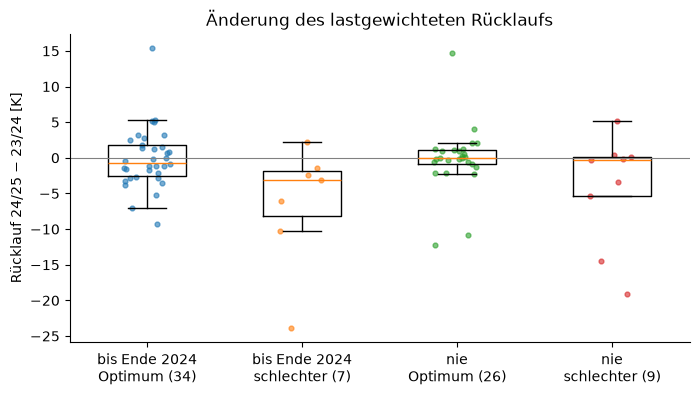

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
positionen, beschriftung = [], []
for i, (schluessel, g) in enumerate(wirkung.groupby(["begangen", "einstufung"])):
    ax.boxplot(g["aenderung_k"], positions=[i], widths=0.5, showfliers=False)
    ax.scatter(np.full(len(g), i) + np.random.default_rng(0).uniform(-0.15, 0.15, len(g)), g["aenderung_k"], s=12, alpha=0.6)
    positionen.append(i)
    beschriftung.append(f"{schluessel[0]}\n{schluessel[1]} ({len(g)})")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(positionen, beschriftung)
ax.set_ylabel("Rücklauf 24/25 − 23/24 [K]")
ax.set_title("Änderung des lastgewichteten Rücklaufs")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Im Optimum ändert sich der Rücklauf kaum, ob begangen oder nicht (Median −0,7 und 0,0 K). In Gruppe B sinkt er deutlich, bei begangenen Stationen im Mittel um 6,4 K (Median −3,1 K, 7 Zähler). Er sinkt aber auch ohne Begehung, bei den nie begangenen Stationen der Gruppe B um 4,1 K (Median −0,3 K, 9 Zähler). Das passt zur Regression zur Mitte: Wer in einem Winter extrem schlecht lag, liegt im nächsten oft weniger extrem, auch ohne Eingriff.

Der Unterschied zwischen begangen und nicht begangen beträgt in Gruppe B nur 2 bis 3 K, bei 7 gegen 9 Stationen. Das lässt sich nicht belastbar trennen. Die Einstufung zeigt, wo Luft nach oben ist, eine Wirkung der Begehung ist hier aber nicht nachweisbar.

## 8 Ergebnis speichern

Die Zelle schreibt Gruppe und Einstufung je Zähler. Notebook 29 kombiniert das mit der Ventil-Erkennung zu den drei Klassen.

In [13]:
daten[MERKMALE + ["gruppe", "einstufung"]].to_csv(PROCESSED / "kmeans_einstufung.csv")
print(daten["einstufung"].value_counts().to_string())

einstufung
Optimum       70
schlechter    18


## Zusammenfassung & Bewertung

**Ergebnis**

Alle 88 Zähler mit genug Wintermessungen sind eingestuft, 70 ins Optimum und 18 als schlechter, nur aus dem Regelverhalten im Winter 23/24 und ohne Label. Das Ergebnis steht in `kmeans_einstufung.csv`. K-Means trennt gut regelnde von konstant durchströmten Stationen, und das ist die vorgegebene Unterscheidung „Optimum gegen schlechter“. Gruppe B ist etwa zur Hälfte das Ventilbild. Für die drei Klassen heißt das: erst das Ventil, dann der Rest. Diese Reihenfolge setzt Notebook 29 um.

**Belastbar**

Die Gruppen sind klar getrennt, mit einer Silhouette von 0,44 bei k = 2, deutlich besser als Notebook 07 mit allen Kennzahlen (unter 0,25). Sie sind auch stabil, über 20 Seeds identisch und im Bootstrap im Median zu 98 % gleich eingestuft.

**Schwach**

Bei den Grenzfällen ist die Einstufung unsicher, im schlechtesten Zwanzigstel der Bootstrap-Läufe bleiben nur 70 % gleich. Die Gegenprobe beim Ventil ergibt 50 % gegen 14 % Ventilbefunde (p = 0,021), nach der Holm-Korrektur ist das nicht mehr signifikant (0,13). Nur 10 begangene Stationen liegen in Gruppe B, jede Aussage über diese Gruppe ruht also auf wenigen Fällen. Über Dämmung, Filter oder Durchfluss sagt die Einstufung nichts. Diese Fehler verändern das Regelverhalten offenbar nicht so, dass es in den drei Größen sichtbar wird.

**Offen**

Gruppe B verbessert sich stark, aber auch ohne Begehung (Regression zur Mitte). Ob die Begehung die Ursache war, ist nicht nachweisbar.